# Milestone 5 — Hero Figure

Prepare a visual summary for the README.

In [1]:
import sys, pathlib
from skimage import data
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
# Works after downloading/extracting the package, or from the project root in Colab.
project_root = pathlib.Path.cwd()
if not (project_root / "src").exists() and (project_root.parent / "src").exists():
    project_root = project_root.parent
sys.path.insert(0, str(project_root / "src"))
from compress import rank_k_approx, storage, compression_ratio, rel_error, predicted_error, k_for_error
(project_root / "figures").mkdir(exist_ok=True)
photo_path = project_root / "data" / "my_photo.png"
if photo_path.exists():
    P = np.array(Image.open(photo_path).convert("L"), dtype=float)
else:
    P = None
    print("No personal photo yet: add data/my_photo.png before final submission.")

## Camera at three ranks

/opt/pyvenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


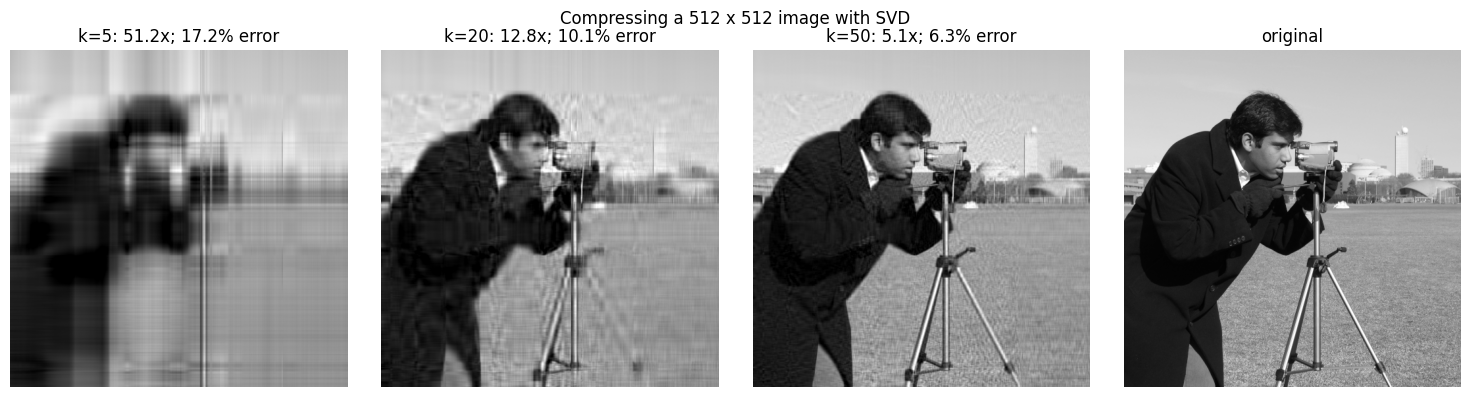

In [2]:
A=data.camera().astype(float);m,n=A.shape
fig,axs=plt.subplots(1,4,figsize=(15,4))
for ax,k in zip(axs,[5,20,50]):
 Ak=np.clip(rank_k_approx(A,k),0,255)
 ax.imshow(Ak,cmap="gray",vmin=0,vmax=255)
 ax.set_title(f"k={k}: {compression_ratio(m,n,k):.1f}x; {100*rel_error(A,Ak):.1f}% error")
 ax.axis("off")
axs[3].imshow(A,cmap="gray",vmin=0,vmax=255);axs[3].set_title("original");axs[3].axis("off")
plt.suptitle("Compressing a 512 x 512 image with SVD");plt.tight_layout()
plt.savefig(project_root/"figures"/"hero.png",dpi=150);plt.show()

The figure uses the public scikit-image camera example, not your own photo. Replace or explain as necessary based on assignment requirements.

## What we found

**To complete after running:** Record the exact output values from the cells above, explain what they mean in your own words, and check your findings against the assignment instructions.